# Course 12: AI for Accessibility
## Session 12: Deploying accessible AI in Bangladesh, and the capstone

**Goal:** train a small isolated-sign recognizer, shrink it with dynamic int8 quantization, measure size, single-thread latency and accuracy before and after, and add a confidence threshold that asks the user to sign again.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. A small sign recognizer, rebuilt for a phone
An assistive app should work **offline** on a low-cost phone: no upload of a person's video, no mobile-data cost, no waiting for a network. That means a small model. We rebuild a smaller version of session 5's isolated-sign recognizer: 12 synthetic signs, each a handshape, a location and a movement, made with a simplified 21-landmark hand (the MediaPipe Hands layout of session 4). Several pairs differ in one parameter only, as minimal pairs do in real sign languages. Sixteen synthetic signers each have their own hand size, speed, movement size and personal way of making every sign, and in 10% of frames the tracker loses the hand, so the previous frame repeats. Signers 0–5 are for training, 6–9 for validation and 10–15 for testing, so every test signer is new.

**The data are synthetic and the signs are not real BdSL signs.** Real data would be consented videos of Deaf signers, run through a hand-landmark tracker.

In [1]:
import io
import time
import warnings
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.set_num_threads(1)
t_start = time.time()
np.random.seed(0)
torch.manual_seed(0)

# a simplified right hand: wrist (0), then thumb, index, middle, ring and little finger, 4 points each (MediaPipe order)
BASE = np.array([[0.25, 0.25], [0.28, 0.95], [0.08, 1.0], [-0.12, 0.95], [-0.30, 0.85]])
ANGLE = np.array([0.9, 0.12, 0.0, -0.12, -0.25])            # direction of each finger in the palm plane
SEG = np.array([[0.35, 0.30, 0.25], [0.45, 0.27, 0.20], [0.50, 0.30, 0.22], [0.47, 0.28, 0.20], [0.37, 0.22, 0.18]])

def hand(curl, spread, size):
    pts = [np.zeros(3)]
    for f in range(5):
        a = ANGLE[f] + spread * (ANGLE[f] - 0.05) * 1.5
        p, bend = np.array([*BASE[f], 0.0]), 0.0
        pts.append(p.copy())
        for L in SEG[f]:
            bend += 1.25 * curl[f]                            # each joint bends the finger towards the palm (-z)
            p = p + L * np.array([np.sin(a) * np.cos(bend), np.cos(a) * np.cos(bend), -np.sin(bend)])
            pts.append(p.copy())
    return np.array(pts) * size

SHAPES = {"B": ([0.6, 0, 0, 0, 0], 0.0), "5": ([0, 0, 0, 0, 0], 1.0), "A": ([0.1, 1, 1, 1, 1], 0.0),
          "1": ([0.8, 0, 1, 1, 1], 0.0), "V": ([0.8, 0, 0, 1, 1], 1.0), "C": ([0.4, 0.5, 0.5, 0.5, 0.5], 0.2)}
LOCATIONS = {"forehead": (0.0, 1.1, 0.25), "chin": (0.0, 0.75, 0.3), "chest": (0.0, 0.0, 0.35), "side": (0.6, 0.2, 0.3)}
def path(kind, s, amp):                                      # s runs from 0 to 1 during the sign
    z = np.zeros_like(s)
    return amp * np.stack({"still": (z, z, z), "forward": (z, z, 0.4 * s), "side": (0.3 * np.sin(2 * np.pi * s), z, z),
                           "updown": (z, 0.25 * np.sin(4 * np.pi * s), z),
                           "circle": (0.2 * np.cos(2 * np.pi * s) - 0.2, 0.2 * np.sin(2 * np.pi * s), z)}[kind], 1)
SIGNS = [("B", "chin", "forward"), ("B", "chest", "forward"), ("B", "chin", "side"), ("5", "chest", "circle"),
         ("A", "chest", "circle"), ("B", "chest", "circle"), ("1", "forehead", "forward"), ("1", "chin", "forward"),
         ("V", "chin", "forward"), ("V", "chest", "side"), ("C", "side", "circle"), ("A", "side", "circle")]
T, N_SIGNS = 24, len(SIGNS)

def make_signer(k):
    r = np.random.default_rng(100 + k)
    return dict(size=r.uniform(0.8, 1.2), amp=r.uniform(0.6, 1.4), dur=r.integers(12, 21),
                loc=r.normal(0, 0.12, (N_SIGNS, 3)), tilt=r.normal(0, 0.3, N_SIGNS), curl=r.normal(0, 0.2, (N_SIGNS, 5)))

def make_sequence(sign, sg, rng):
    shape, loc, move = SIGNS[sign]
    curl, spread = SHAPES[shape]
    start = rng.integers(1, T - sg["dur"])
    s = np.clip((np.arange(T) - start) / sg["dur"], 0, 1)      # hold still before and after the sign
    pts = hand(np.clip(np.array(curl) + sg["curl"][sign] + rng.normal(0, 0.05, 5), 0, 1.1), spread, sg["size"])
    c, sn = np.cos(sg["tilt"][sign]), np.sin(sg["tilt"][sign])
    pts = pts @ np.array([[c, -sn, 0], [sn, c, 0], [0, 0, 1]]).T * 0.35        # hand about a third of a shoulder width
    centre = np.array(LOCATIONS[loc]) + sg["loc"][sign] + path(move, s, sg["amp"] * rng.uniform(0.85, 1.15))
    seq = centre[:, None, :] + pts[None] + rng.normal(0, 0.03, (T, 21, 3))
    for t in np.where(rng.random(T) < 0.1)[0]:
        if t > 0:
            seq[t] = seq[t - 1]                                # the tracker lost the hand: the previous frame repeats
    return seq.reshape(T, 63).astype(np.float32)

def make_split(signers, reps, seed):
    rng = np.random.default_rng(seed)
    X, y, who, rep_no = [], [], [], []
    for k in signers:
        sg = make_signer(k)
        for rep in range(reps):
            for sign in range(N_SIGNS):
                X.append(make_sequence(sign, sg, rng)); y.append(sign); who.append(k); rep_no.append(rep)
    return np.array(X), np.array(y), np.array(who), np.array(rep_no)

X_tr, y_tr, _, _ = make_split(range(6), 8, seed=1)
X_va, y_va, _, _ = make_split(range(6, 10), 8, seed=2)
X_te, y_te, w_te, r_te = make_split(range(10, 16), 8, seed=3)
MU, SD = X_tr.reshape(-1, 63).mean(0), X_tr.reshape(-1, 63).std(0) + 1e-6
norm = lambda X: torch.tensor((X - MU) / SD)
print(f"sequences: {len(y_tr)} training (6 signers), {len(y_va)} validation (4 signers), {len(y_te)} test (6 new signers); "
      f"each {T} frames x 21 landmarks x 3 coordinates")

sequences: 576 training (6 signers), 384 validation (4 signers), 576 test (6 new signers); each 24 frames x 21 landmarks x 3 coordinates


### 2. Train the recognizer
A bidirectional GRU (hidden size 48) reads the 24 frames, its outputs are averaged over time, and a linear layer scores the 12 signs. All sequences have the same length, so no padding or masking is needed here (session 5 covers variable lengths).

In [2]:
class SignGRU(nn.Module):
    def __init__(self, hidden=48):
        super().__init__()
        self.gru = nn.GRU(63, hidden, batch_first=True, bidirectional=True)
        self.out = nn.Linear(2 * hidden, N_SIGNS)
    def forward(self, x):
        z, _ = self.gru(x)
        return self.out(z.mean(1))

model = SignGRU()
opt = torch.optim.Adam(model.parameters(), lr=3e-3)
Xt, yt, gen = norm(X_tr), torch.tensor(y_tr), torch.Generator().manual_seed(0)
t0 = time.time()
for epoch in range(30):
    perm = torch.randperm(len(yt), generator=gen)
    for i in range(0, len(yt), 32):
        idx = perm[i:i + 32]
        loss = F.cross_entropy(model(Xt[idx]), yt[idx])
        opt.zero_grad(); loss.backward(); opt.step()
model.eval()
with torch.no_grad():
    p_va, p_te = F.softmax(model(norm(X_va)), 1), F.softmax(model(norm(X_te)), 1)
print(f"{sum(p.numel() for p in model.parameters()):,} parameters, trained in {time.time() - t0:.0f} s")
print(f"accuracy: validation signers {(p_va.argmax(1).numpy() == y_va).mean():.3f}, new test signers {(p_te.argmax(1).numpy() == y_te).mean():.3f}")

33,708 parameters, trained in 6 s
accuracy: validation signers 0.883, new test signers 0.943


### 3. Dynamic int8 quantization: size, speed and accuracy
**Dynamic quantization** stores the weights of the GRU and linear layers as 8-bit integers with a scale, instead of 32-bit floats, and quantizes the activations while the model runs (Course 5 session 10; Course 11 sessions 3 and 4 go deeper). It needs no retraining and no extra data. We measure:

* **size:** the bytes of the saved weights;
* **latency:** the time to recognize one sign on **one CPU thread**, the median of 500 runs after a warm-up (a phone's cores are slower than this machine's; measure on the target phone, Course 11 session 11);
* **accuracy** on the new signers, and how often the two models agree.

Recent PyTorch versions print a deprecation warning for `torch.ao.quantization`, because quantization is moving to the separate `torchao` library; the function still works, and we hide the warning to keep the output readable.

In [3]:
warnings.filterwarnings("ignore", message=".*torch.ao.quantization is deprecated.*")
warnings.filterwarnings("ignore", message=".*quantize_per_tensor.*")
qmodel = torch.ao.quantization.quantize_dynamic(model, {nn.GRU, nn.Linear}, dtype=torch.qint8)

def saved_bytes(m):
    buf = io.BytesIO(); torch.save(m.state_dict(), buf); return buf.tell()

def latencies_ms(models, x, runs=500):
    # time the models in turn (A, B, A, B, ...) so that a busy moment on a shared machine hits both alike
    times = {name: [] for name in models}
    with torch.no_grad():
        for m in models.values():
            for _ in range(30):
                m(x)                                          # warm-up
        for _ in range(runs):
            for name, m in models.items():
                t = time.perf_counter(); m(x); times[name].append(1000 * (time.perf_counter() - t))
    return {name: np.percentile(v, [25, 50, 75]) for name, v in times.items()}

with torch.no_grad():
    q_va, q_te = F.softmax(qmodel(norm(X_va)), 1), F.softmax(qmodel(norm(X_te)), 1)
lat = latencies_ms({"float32": model, "int8 dynamic": qmodel}, norm(X_te[:1]))
results = {}
for name, m, p in [("float32", model, p_te), ("int8 dynamic", qmodel, q_te)]:
    results[name] = (saved_bytes(m), lat[name][1], (p.argmax(1).numpy() == y_te).mean())
    print(f"{name:13s}: {results[name][0]:7,d} bytes, {lat[name][1]:.3f} ms per sign (median of 500, 1 thread; middle half "
          f"{lat[name][0]:.3f} to {lat[name][2]:.3f}), accuracy on new signers {results[name][2]:.3f}")
print(f"size ratio {results['float32'][0] / results['int8 dynamic'][0]:.2f}x, speed ratio "
      f"{results['float32'][1] / results['int8 dynamic'][1]:.2f}x; the two models agree on "
      f"{(p_te.argmax(1) == q_te.argmax(1)).float().mean():.3f} of test signs; largest probability change {(p_te - q_te).abs().max():.4f}")
print(qmodel)

float32      : 138,309 bytes, 0.864 ms per sign (median of 500, 1 thread; middle half 0.821 to 0.926), accuracy on new signers 0.943
int8 dynamic :  40,383 bytes, 0.845 ms per sign (median of 500, 1 thread; middle half 0.801 to 0.930), accuracy on new signers 0.941
size ratio 3.42x, speed ratio 1.02x; the two models agree on 0.998 of test signs; largest probability change 0.0880
SignGRU(
  (gru): DynamicQuantizedGRU(63, 48, batch_first=True, bidirectional=True)
  (out): DynamicQuantizedLinear(in_features=96, out_features=12, dtype=torch.qint8, qscheme=torch.per_tensor_affine)
)


### 4. Asking the user to sign again
A wrong word in a conversation is worse than a short pause. The app can **abstain**: if the highest probability is below a threshold, it says "please sign again". We choose the lowest threshold whose answered **validation** signs are at least 98% correct, then report on the new test signers the **coverage** (share of signs answered at the first attempt) and the accuracy on those. Then we compare three policies: always answer; ask once for a repeat (the same signer's next repetition of the same sign) and answer whatever comes; and ask once, then, if the model is still unsure, show the three most likely signs as buttons for the user to choose from (as word prediction does in session 10).

float32: threshold 0.995; first attempt answered 0.684 at accuracy 0.964; the unsure ones: first attempt 0.896, repeat 0.896
   always answer                  : final accuracy 0.943, 1.00 attempts per sign, choice list shown for 0.000
   ask once, then answer          : final accuracy 0.943, 1.32 attempts per sign, choice list shown for 0.000
   ask once, then offer 3 choices : final accuracy 0.958, 1.32 attempts per sign, choice list shown for 0.276
int8 dynamic: threshold 0.995; first attempt answered 0.682 at accuracy 0.962; the unsure ones: first attempt 0.896, repeat 0.896
   always answer                  : final accuracy 0.941, 1.00 attempts per sign, choice list shown for 0.000
   ask once, then answer          : final accuracy 0.941, 1.32 attempts per sign, choice list shown for 0.000
   ask once, then offer 3 choices : final accuracy 0.958, 1.32 attempts per sign, choice list shown for 0.276
test signer 10: float32 accuracy 0.990, int8 0.990
test signer 11: float32 accuracy 0

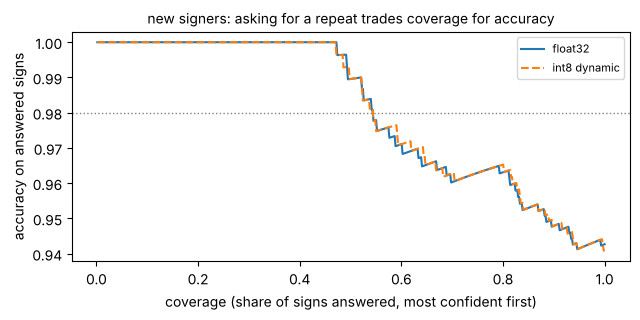

runtime so far 9 s


In [4]:
def threshold_for(p, y, target=0.98):
    conf, correct = p.max(1).values.numpy(), (p.argmax(1).numpy() == y)
    order = np.argsort(-conf)
    acc = np.cumsum(correct[order]) / np.arange(1, len(order) + 1)
    k = np.where(acc >= target)[0].max()
    return conf[order][k]

index = {(k, r, s): i for i, (k, r, s) in enumerate(zip(w_te, r_te, y_te))}
retry = np.array([index[(k, (r + 1) % 8, s)] for k, r, s in zip(w_te, r_te, y_te)])   # same signer, same sign, next repetition

def policies(p, y, thr):
    conf, pred, top3 = p.max(1).values.numpy(), p.argmax(1).numpy(), p.topk(3, 1).indices.numpy()
    sure = conf >= thr
    sure2 = conf[retry] >= thr                                     # is the model sure about the repeat?
    in_top3 = np.array([y[i] in top3[retry[i]] for i in range(len(y))])
    out = {"always answer": ((pred == y).mean(), 1.0, 0.0),
           "ask once, then answer": (np.where(sure, pred == y, pred[retry] == y).mean(), 1 + (~sure).mean(), 0.0),
           "ask once, then offer 3 choices": (np.where(sure, pred == y, np.where(sure2, pred[retry] == y, in_top3)).mean(),
                                               1 + (~sure).mean(), (~sure & ~sure2).mean())}
    return sure, out

curves = {}
for name, pv, pt in [("float32", p_va, p_te), ("int8 dynamic", q_va, q_te)]:
    thr = threshold_for(pv, y_va)
    sure, out = policies(pt, y_te, thr)
    pred = pt.argmax(1).numpy()
    print(f"{name}: threshold {thr:.3f}; first attempt answered {sure.mean():.3f} at accuracy {(pred[sure] == y_te[sure]).mean():.3f}; "
          f"the unsure ones: first attempt {(pred[~sure] == y_te[~sure]).mean():.3f}, repeat {(pred[retry][~sure] == y_te[~sure]).mean():.3f}")
    for policy, (acc, attempts, choices) in out.items():
        print(f"   {policy:31s}: final accuracy {acc:.3f}, {attempts:.2f} attempts per sign, choice list shown for {choices:.3f}")
    conf, correct = pt.max(1).values.numpy(), (pt.argmax(1).numpy() == y_te)
    o = np.argsort(-conf)
    curves[name] = (np.arange(1, len(o) + 1) / len(o), np.cumsum(correct[o]) / np.arange(1, len(o) + 1))
for k in range(10, 16):
    m = w_te == k
    print(f"test signer {k}: float32 accuracy {(p_te.argmax(1).numpy()[m] == y_te[m]).mean():.3f}, "
          f"int8 {(q_te.argmax(1).numpy()[m] == y_te[m]).mean():.3f}")

plt.figure(figsize=(6.5, 3.3))
for (name, (cov, acc)), ls in zip(curves.items(), ["-", "--"]):
    plt.plot(cov, acc, ls, label=name)
plt.axhline(0.98, color="0.5", ls=":", lw=1)
plt.xlabel("coverage (share of signs answered, most confident first)"); plt.ylabel("accuracy on answered signs")
plt.title("new signers: asking for a repeat trades coverage for accuracy", fontsize=10); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"runtime so far {time.time() - t_start:.0f} s")

### 5. Putting it on a phone (NOT RUN here)
To run the model in an Android app, export it to a portable format and use an on-device runtime. Course 11 (On-Device AI) covers formats and runtimes in session 7 and honest benchmarking in session 11. The cell below exports to ONNX and checks the result with ONNX Runtime; it needs `pip install onnx onnxscript onnxruntime`.

In [ ]:
# NOT RUN: needs onnx, onnxscript and onnxruntime (pip install onnx onnxscript onnxruntime); see Course 11 session 7
import onnxruntime as ort

example = norm(X_te[:1])
torch.onnx.export(model, (example,), "sign_gru.onnx", dynamo=True)       # export the float32 model
session = ort.InferenceSession("sign_gru.onnx", providers=["CPUExecutionProvider"])
name = session.get_inputs()[0].name
onnx_out = session.run(None, {name: example.numpy()})[0]
print("max difference from PyTorch:", np.abs(onnx_out - model(example).detach().numpy()).max())

### 6. Exercises

In [5]:
# TODO: the smallest model that is good enough. Train SignGRU with hidden sizes 8, 16, 32 and 48 (and, if you like,
# a 1-D convolutional model), quantize each, and make a table of parameters, int8 bytes, single-thread latency and
# accuracy on the new signers. Which is the smallest model within 2 points of the best accuracy? Use the same seed.
def size_sweep():
    return None          # replace with your code; return the table

r = size_sweep()
print("not done yet" if r is None else r)

not done yet


In [6]:
# TODO: does quantization hurt some users more? Using session 11's bootstrap, put 95% intervals on the float32 and int8
# accuracy for each test signer, and on the per-signer DIFFERENCE between the two models (a paired bootstrap over
# that signer's test signs). Is any difference clearly different from zero? What would you need to be sure?
def per_signer_quantization_check():
    return None          # replace with your code

r = per_signer_quantization_check()
print("not done yet" if r is None else r)

not done yet


### What to notice
(Written from the run above. Accuracies and sizes will match if you keep the seeds; latencies change from run to run.)

1. **New signers are the real test.** The 33,708-parameter GRU trained in seconds and scored 0.943 on the six new test signers, but only 0.883 on the four validation signers, and from 0.833 to 1.000 for individual test signers. With so few signers, which people you test on changes the answer (session 11).
2. **Quantization shrank the model without hurting it.** Dynamic int8 quantization cut the saved weights 3.42 times, from 138,309 to 40,383 bytes. Accuracy went from 0.943 to 0.941: the two models disagreed on one test sign in 576 (agreement 0.998), and no probability changed by more than 0.088.
3. **It did not make this model meaningfully faster.** The two median latencies on one thread were within a few percent of each other, and the middle halves of their timings overlapped. For a model this small, much of the time goes into overheads rather than weight arithmetic, and timings on a shared machine vary from run to run. Speed must be measured on the target phone, with repeated, interleaved runs (Course 11 session 11).
4. **A threshold chosen on some signers is not a promise for others.** The threshold chosen for 98% accuracy on the validation signers (0.995) answered 0.684 of the new signers' signs at the first attempt, with accuracy 0.964, below the 98% aimed for.
5. **Against expectation, asking for a repeat did not help.** The signs the model was unsure about were right 0.896 of the time at the first attempt and 0.896 on the repeat, so "ask once, then answer" ended at the same accuracy as always answering (0.943) while costing 1.32 attempts per sign. The errors come from each signer's personal way of making a sign, and a repeat by the same person reproduces it. Offering the three most likely signs after an unsure repeat raised the final accuracy to 0.958, with a choice list on 0.276 of the signs. A real fix is more diverse training signers, or a few examples from each user (personalization), chosen and tested with Deaf users.